# Plant Disease Detection — PyTorch (Kaggle, No Augmentation)

Beginner-friendly project comparing **a custom CNN** and **pretrained MobileNetV2**.

- No additional data augmentation
- Simple text updates during training (no progress bar library)
- Custom CNN: **maximum 15 epochs**; MobileNetV2: **maximum 8 epochs**
- Early stopping after **3 consecutive epochs** without lower validation loss
- Train/validation accuracy and loss, two graphs and best model weights

## Run on Kaggle

1. Import the notebook into Kaggle.
2. Attach [New Plant Diseases Dataset](https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset) from Add Input.
3. Enable a GPU in the Kaggle session settings.
4. Enable Internet if pretrained MobileNetV2 weights must be downloaded.
5. Click Run All.

**Note:** The source dataset already contains augmented images. This notebook does not perform any further augmentation. The provided validation set may overestimate performance on new real-world photos.

## Step 1 — Import libraries

- `torch`: builds and trains neural networks.
- `torchvision`: reads image folders and provides MobileNetV2.
- `matplotlib`: makes our accuracy and loss graphs.
- `Path`: helps us find Kaggle dataset folders and save output files.

All are normally available in Kaggle's Python environment, so **no `pip install` cell** is required.

In [11]:
import os
import json
import csv
import zipfile
from pathlib import Path

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import datasets, transforms, models

print('PyTorch version:', torch.__version__)

PyTorch version: 2.11.0+cu130


## Step 2 — Settings

- Image size: **160 × 160**
- Batch size: **64**
- Custom CNN: **maximum 15 epochs**
- MobileNetV2: **maximum 8 epochs**
- Early stopping patience: **3 epochs** (based on validation loss)
- GPU required
- No extra data augmentation

In [12]:
IMAGE_SIZE = 160
BATCH_SIZE = 64
CNN_EPOCHS = 15
MOBILENET_EPOCHS = 8
PATIENCE = 3  # Stop if validation loss does not improve for 3 epochs

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE != 'cuda':
    raise RuntimeError('GPU is OFF! In Kaggle, open Settings and set Accelerator to GPU, then Run All.')

OUTPUT_DIR = Path('/kaggle/working')
MODEL_DIR = OUTPUT_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

torch.manual_seed(42)
torch.backends.cudnn.benchmark = True  # Helps with fixed-size images.

print('Device:', DEVICE, flush=True)
print('GPU:', torch.cuda.get_device_name(0), flush=True)
print('Batch size:', BATCH_SIZE, flush=True)
print('Data augmentation: OFF', flush=True)
print('Output folder:', OUTPUT_DIR, flush=True)

Device: cuda
GPU: Tesla T4
Batch size: 64
Data augmentation: OFF
Output folder: /kaggle/working


## Step 3 — Find Kaggle dataset automatically

After you attach the dataset in the **Input** panel, Kaggle places it under `/kaggle/input/`.

The script searches for the matching `train/` and `valid/` class folders, regardless of the nested dataset folder name.
**You do not need to type a path.**

In [13]:
input_folder = Path('/kaggle/input/datasets/vipoooool/new-plant-diseases-dataset')
if not input_folder.exists():
    raise FileNotFoundError(
        'Dataset is not attached. In Kaggle, open Input → Add Input → '
        'search "New Plant Diseases Dataset" by vipoooool, then add it.'
    )

train_dir = None
valid_dir = None

for folder, subfolders, files in os.walk(input_folder):
    if 'train' in subfolders and 'valid' in subfolders:
        train_dir = Path(folder) / 'train'
        valid_dir = Path(folder) / 'valid'
        break

if train_dir is None:
    raise FileNotFoundError('Could not find train/ and valid/ in the attached dataset.')

print('Train folder:', train_dir)
print('Valid folder:', valid_dir)

Train folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train
Valid folder: /kaggle/input/datasets/vipoooool/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid


## Step 4 — Load images (no data augmentation)

- `ImageFolder` reads the existing images inside their class folders.
- `Resize` makes every photo **160 × 160 pixels**, which the models expect.
- `ToTensor` converts a photo into a PyTorch tensor.
- `Normalize` uses the standard ImageNet values required by pretrained MobileNetV2.

**These are preprocessing steps, not augmentation**: no new image angles, flips, crops, or duplicates are created.

We apply the **same preprocessing** to training and validation images. The `DataLoader` shuffles training images only, not validation images.

In [14]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Basic preprocessing only — no rotation, flips, or other augmentation.
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_data = datasets.ImageFolder(train_dir, transform=image_transform)
valid_data = datasets.ImageFolder(valid_dir, transform=image_transform)

class_names = train_data.classes
assert class_names == valid_data.classes, 'Training and validation class names do not match.'
num_classes = len(class_names)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True, persistent_workers=True
)
valid_loader = DataLoader(
    valid_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True, persistent_workers=True
)

with open(MODEL_DIR / 'class_names.json', 'w') as file:
    json.dump(class_names, file, indent=2)

print('Number of classes:', num_classes)
print('Training images per epoch:', len(train_data))
print('Validation images:', len(valid_data))
print('Training batches per epoch:', len(train_loader))
print('Validation batches per epoch:', len(valid_loader))

Number of classes: 38
Training images per epoch: 70295
Validation images: 17572
Training batches per epoch: 1099
Validation batches per epoch: 275


## Step 5 — Model 1: build your own simple CNN

This is a small model you can explain in an interview:

| Layer | What it does |
|---|---|
| `Conv2d` | Detects features such as lines and spots |
| `ReLU` | Adds non-linearity to learn complex patterns |
| `MaxPool2d` | Reduces the size of feature maps |
| `AdaptiveAvgPool2d` | Reduces each feature map to one number |
| `Flatten` | Turns feature maps into a vector |
| `Dropout` | Helps reduce overfitting |
| `Linear` | Predicts the image class |

In [15]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )

    def forward(self, images):
        return self.layers(images)

cnn = SimpleCNN(num_classes)
print('Custom CNN created!')

Custom CNN created!


## Step 6 — Model 2: pretrained MobileNetV2

**Transfer learning:** use image features that MobileNetV2 already learned from a large image dataset.

- `weights=DEFAULT`: load pretrained ImageNet weights (**Internet may be needed once**).
- `requires_grad = False`: freeze the feature extractor to make training simpler and faster.
- `Linear(..., num_classes)`: train a new classifier for the 38 plant disease classes.

The final layer is trained, but the pretrained feature-extraction layers remain frozen.

In [16]:
try:
    mobilenet = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
except Exception as error:
    raise RuntimeError(
        'Could not load pretrained MobileNetV2 weights. '
        'Enable Internet in Kaggle Settings and rerun this cell. '
        'The pretrained model cannot work as intended without those weights.'
    ) from error

for parameter in mobilenet.features.parameters():
    parameter.requires_grad = False

mobilenet.classifier[1] = nn.Linear(mobilenet.last_channel, num_classes)
print('Pretrained MobileNetV2 created!')

Pretrained MobileNetV2 created!


## Step 7 — Train with simple text output + early stopping

The training loop prints one short line every **200 batches** — no progress bars.

**Early stopping** watches *validation loss* after every completed epoch. If it does not decrease for **3 consecutive epochs**, training stops. The notebook saves the weights from the **lowest validation-loss epoch**, even if training stops early.


In [17]:
def train_model(model, model_name, learning_rate, num_epochs):
    model = model.to(DEVICE)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=learning_rate
    )

    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_loss = float('inf')
    no_improvement = 0

    for epoch in range(num_epochs):
        print(f'\n{model_name.upper()} - Epoch {epoch + 1}/{num_epochs}', flush=True)
        model.train()

        # The pretrained MobileNetV2 feature extractor stays frozen.
        if model_name == 'mobilenet':
            model.features.eval()

        train_loss, train_correct, train_total = 0, 0, 0

        for batch_number, (images, labels) in enumerate(train_loader, start=1):
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * len(labels)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += len(labels)

            if batch_number % 200 == 0 or batch_number == len(train_loader):
                print(f'Training batch {batch_number}/{len(train_loader)}', flush=True)

        model.eval()
        val_loss, val_correct, val_total = 0, 0, 0

        with torch.no_grad():
            for images, labels in valid_loader:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE)
                outputs = model(images)
                loss = loss_fn(outputs, labels)

                val_loss += loss.item() * len(labels)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += len(labels)

        history['train_loss'].append(train_loss / train_total)
        history['train_acc'].append(100 * train_correct / train_total)
        history['val_loss'].append(val_loss / val_total)
        history['val_acc'].append(100 * val_correct / val_total)

        accuracy = history['val_acc'][-1]
        current_val_loss = history['val_loss'][-1]

        if current_val_loss < best_val_loss:
            best_val_loss = current_val_loss
            no_improvement = 0
            torch.save(model.state_dict(), MODEL_DIR / f'{model_name}_best.pth')
            print('Best model saved.', flush=True)
        else:
            no_improvement += 1

        print(f'Train Loss: {history["train_loss"][-1]:.3f} | Train Acc: {history["train_acc"][-1]:.2f}%', flush=True)
        print(f'Val Loss:   {current_val_loss:.3f} | Val Acc:   {accuracy:.2f}%', flush=True)

        if no_improvement >= PATIENCE:
            print(f'Early stopping: validation loss did not improve for {PATIENCE} epochs.', flush=True)
            break

    return history

## Step 8 — Train both models

The custom CNN trains for **up to 15 epochs**, then MobileNetV2 trains for **up to 8 epochs**. Each model stops earlier if validation loss fails to improve for 3 consecutive epochs. A short text update appears every 200 batches, followed by an accuracy/loss summary after each epoch.


In [18]:
cnn_history = train_model(cnn, 'cnn', 0.001, CNN_EPOCHS)


CNN - Epoch 1/15
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 1.806 | Train Acc: 47.40%
Val Loss:   0.969 | Val Acc:   71.81%

CNN - Epoch 2/15
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.928 | Train Acc: 71.73%
Val Loss:   0.607 | Val Acc:   82.67%

CNN - Epoch 3/15
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.689 | Train Acc: 78.78%
Val Loss:   0.462 | Val Acc:   86.93%

CNN - Epoch 4/15
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.573 | Train Acc: 82.34%
Val Lo

In [19]:
mobilenet_history = train_model(mobilenet, 'mobilenet', 0.0005, MOBILENET_EPOCHS)


MOBILENET - Epoch 1/8
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.800 | Train Acc: 84.93%
Val Loss:   0.352 | Val Acc:   92.14%

MOBILENET - Epoch 2/8
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.295 | Train Acc: 92.79%
Val Loss:   0.234 | Val Acc:   94.21%

MOBILENET - Epoch 3/8
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.222 | Train Acc: 94.20%
Val Loss:   0.189 | Val Acc:   95.00%

MOBILENET - Epoch 4/8
Training batch 200/1099
Training batch 400/1099
Training batch 600/1099
Training batch 800/1099
Training batch 1000/1099
Training batch 1099/1099
Best model saved.
Train Loss: 0.184 | Trai

## Step 9 — Create the **two requested graphs**

- **Graph 1:** train and validation accuracy (both models).
- **Graph 2:** train and validation loss (both models).

The graphs are shown below and are also saved as PNG files in `/kaggle/working`.

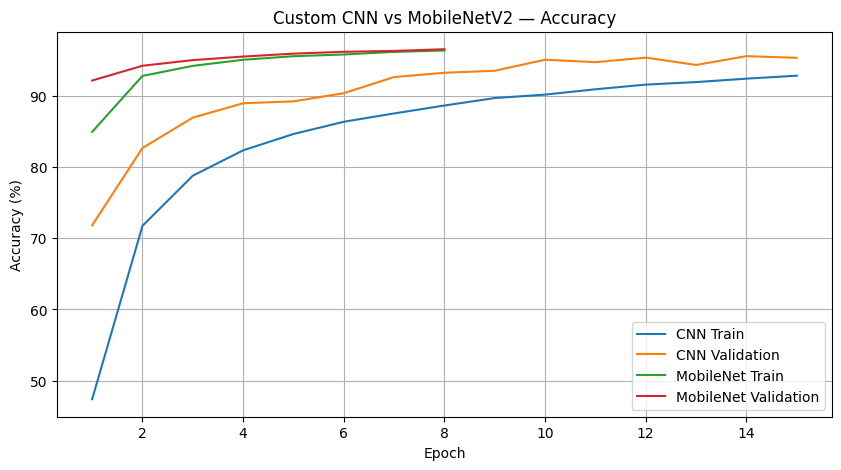

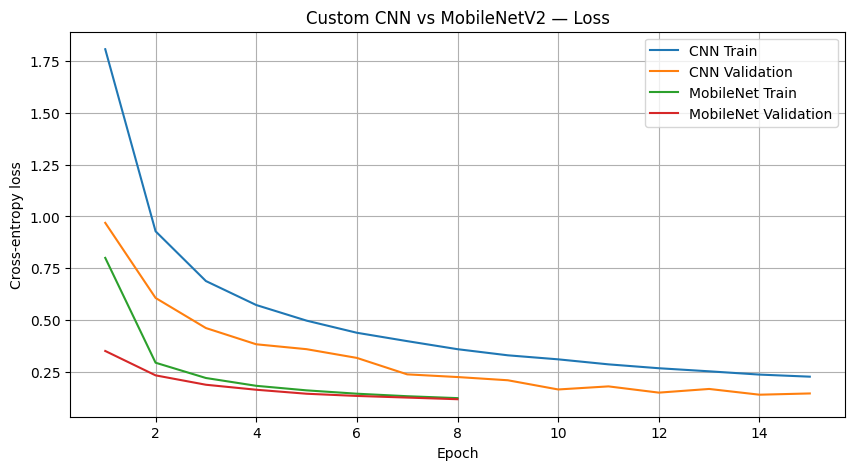

In [20]:
cnn_epochs = range(1, len(cnn_history["train_acc"]) + 1)
mobile_epochs = range(1, len(mobilenet_history["train_acc"]) + 1)

# Graph 1 — Accuracy
plt.figure(figsize=(10, 5))
plt.plot(cnn_epochs, cnn_history['train_acc'], label='CNN Train')
plt.plot(cnn_epochs, cnn_history['val_acc'], label='CNN Validation')
plt.plot(mobile_epochs, mobilenet_history['train_acc'], label='MobileNet Train')
plt.plot(mobile_epochs, mobilenet_history['val_acc'], label='MobileNet Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Custom CNN vs MobileNetV2 — Accuracy')
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_DIR / 'accuracy_comparison.png', bbox_inches='tight')
plt.show()

# Graph 2 — Loss
plt.figure(figsize=(10, 5))
plt.plot(cnn_epochs, cnn_history['train_loss'], label='CNN Train')
plt.plot(cnn_epochs, cnn_history['val_loss'], label='CNN Validation')
plt.plot(mobile_epochs, mobilenet_history['train_loss'], label='MobileNet Train')
plt.plot(mobile_epochs, mobilenet_history['val_loss'], label='MobileNet Validation')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('Custom CNN vs MobileNetV2 — Loss')
plt.legend()
plt.grid(True)
plt.savefig(OUTPUT_DIR / 'loss_comparison.png', bbox_inches='tight')
plt.show()

## Step 10 — Compare the saved models' validation accuracy

We saved each model from the **lowest validation-loss epoch**, so the table compares the validation accuracy at that saved checkpoint (which may not be the epoch with the highest accuracy). Results are written to `model_comparison.csv`.


In [21]:
# Select the epoch whose weights were saved (lowest validation loss).
cnn_best_epoch = cnn_history['val_loss'].index(min(cnn_history['val_loss']))
mobile_best_epoch = mobilenet_history['val_loss'].index(min(mobilenet_history['val_loss']))

cnn_best = cnn_history['val_acc'][cnn_best_epoch]
mobile_best = mobilenet_history['val_acc'][mobile_best_epoch]

print(f'Custom CNN saved-model validation accuracy: {cnn_best:.2f}% (epoch {cnn_best_epoch + 1})')
print(f'MobileNetV2 saved-model validation accuracy: {mobile_best:.2f}% (epoch {mobile_best_epoch + 1})')
print('Higher saved-model validation accuracy:',
      'MobileNetV2' if mobile_best >= cnn_best else 'Custom CNN')

with open(OUTPUT_DIR / 'model_comparison.csv', 'w', newline='') as file:
    writer = csv.writer(file)
    writer.writerow(['model', 'saved_epoch', 'validation_accuracy_percent'])
    writer.writerow(['Custom CNN', cnn_best_epoch + 1, round(cnn_best, 2)])
    writer.writerow(['MobileNetV2', mobile_best_epoch + 1, round(mobile_best, 2)])

print('Results saved to:', OUTPUT_DIR / 'model_comparison.csv')


Custom CNN saved-model validation accuracy: 95.56% (epoch 14)
MobileNetV2 saved-model validation accuracy: 96.53% (epoch 8)
Higher saved-model validation accuracy: MobileNetV2
Results saved to: /kaggle/working/model_comparison.csv


## Step 11 — Package the trained MobileNetV2 for your website

Your included Streamlit website loads:

- `models/mobilenet_best.pth` — the trained MobileNetV2 model.
- `models/class_names.json` — the 38 class labels in order.

The ZIP created below has the **correct `models/` folder** inside. Download it from the Kaggle **Output** panel and extract it into your local GitHub project folder. No code changes in `app.py` are needed.

In [22]:
zip_path = OUTPUT_DIR / 'website_model.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    z.write(MODEL_DIR / 'mobilenet_best.pth', arcname='models/mobilenet_best.pth')
    z.write(MODEL_DIR / 'class_names.json', arcname='models/class_names.json')

print('Website model package:', zip_path)
print('Other Kaggle outputs:')
for name in ['accuracy_comparison.png', 'loss_comparison.png', 'model_comparison.csv']:
    print(' -', OUTPUT_DIR / name)
print('In Kaggle, save the notebook version so its outputs are retained.')

Website model package: /kaggle/working/website_model.zip
Other Kaggle outputs:
 - /kaggle/working/accuracy_comparison.png
 - /kaggle/working/loss_comparison.png
 - /kaggle/working/model_comparison.csv
In Kaggle, save the notebook version so its outputs are retained.
